# Data Preprocessing

This notebook documents the data preparation steps for two supervised learning tasks on the Ames Housing dataset. The first predicts the year a house was built (regression), and the second classifies houses by architectural typology (classification). The processed splits are exported for use in the modelling notebooks.

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import skew, kurtosis
import pickle

from sklearn.preprocessing import (PowerTransformer, StandardScaler,
                                    MinMaxScaler, OneHotEncoder, OrdinalEncoder)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from category_encoders import BinaryEncoder
from sklearn.model_selection import train_test_split

## Data Loading and Initial Cleaning

The raw CSV is loaded and inspected for missing values. Columns missing more than 70% of their entries are removed at this stage, since imputing at that level of missingness would introduce more noise than signal.

In [36]:
df = pd.read_csv('AmesHousing.csv')
print(f'Shape: {df.shape}')
df.head(5)

Shape: (2930, 82)


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [37]:
df.isnull().sum()

Order               0
PID                 0
MS SubClass         0
MS Zoning           0
Lot Frontage      490
                 ... 
Mo Sold             0
Yr Sold             0
Sale Type           0
Sale Condition      0
SalePrice           0
Length: 82, dtype: int64

In [ ]:
threshhold = 0.70
missing = df.isnull().mean()
print('Dropped columns (>70% missing):')
print(missing[missing > threshhold])
# 70% is a conventional cutoff: above this level, imputed values would outnumber
# genuine observations for the column, making the imputation itself the dominant signal.
df.drop(columns=missing[missing > threshhold].index, inplace=True)
print(f'Shape after drop: {df.shape}')

Dropped columns (>70% missing):
Alley           0.932423
Pool QC         0.995563
Fence           0.804778
Misc Feature    0.963823
dtype: float64
Shape after drop: (2930, 78)


## Feature Engineering

A derived variable, `Year Remod/Add Delta`, is calculated as the difference between the remodel year and the original build year. This captures how recently a house was renovated relative to its construction date, without retaining the raw remodel year as a predictor.

`House Style` is copied to a separate series before the column is removed from the shared feature set. This preserves it as the classification target without it appearing as a predictor for the regression task.

Two data quality issues are corrected at this stage. One record lists `Garage Yr Blt` as 2207, which exceeds every `Year Built` value in the dataset and is an evident transcription error; rather than guessing at the intended value, it is set to missing so the pipeline's median imputer handles it. A second record has a negative `Year Remod/Add Delta`, which is not physically possible since a remodel cannot occur before construction; this value is clipped to zero.

In [40]:
df.dropna(subset=['Year Built', 'House Style'], inplace=True)

# Data quality correction: one record has Garage Yr Blt = 2207, which exceeds
# the maximum Year Built in the dataset and is almost certainly a transcription
# error for 2007. It is set to missing rather than silently left in place, so
# the pipeline's median imputer (fit on the training fold only) replaces it.
df.loc[df['Garage Yr Blt'] > df['Year Built'].max(), 'Garage Yr Blt'] = np.nan

df['Year Remod/Add Delta'] = df['Year Remod/Add'] - df['Year Built']
# A remodel cannot predate construction; one record has Delta = -1 due to a
# recording inconsistency. Negative deltas are clipped to 0 (no remodel).
df['Year Remod/Add Delta'] = df['Year Remod/Add Delta'].clip(lower=0)

house_style_target = df['House Style'].copy()
df.drop(columns=['Order', 'PID', 'SalePrice', 'House Style',
                 'Year Remod/Add', 'Yr Sold', 'Mo Sold'], inplace=True)
print(f'Shape: {df.shape}')
df.head(3)

Shape: (2930, 72)


,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Sale Type,Sale Condition,Year Remod/Add Delta
0,20,RL,141.0,31770,Pave,IR1,Lvl,AllPub,Corner,Gtl,...,210,62,0,0,0,0,0,WD,Normal,0
1,20,RH,80.0,11622,Pave,Reg,Lvl,AllPub,Inside,Gtl,...,140,0,0,0,120,0,0,WD,Normal,0
2,20,RL,81.0,14267,Pave,IR1,Lvl,AllPub,Corner,Gtl,...,393,36,0,0,0,0,12500,WD,Normal,0


## Exploratory Data Analysis

The two target variables are examined first, followed by the relationships between the main numerical predictors and `Year Built`.

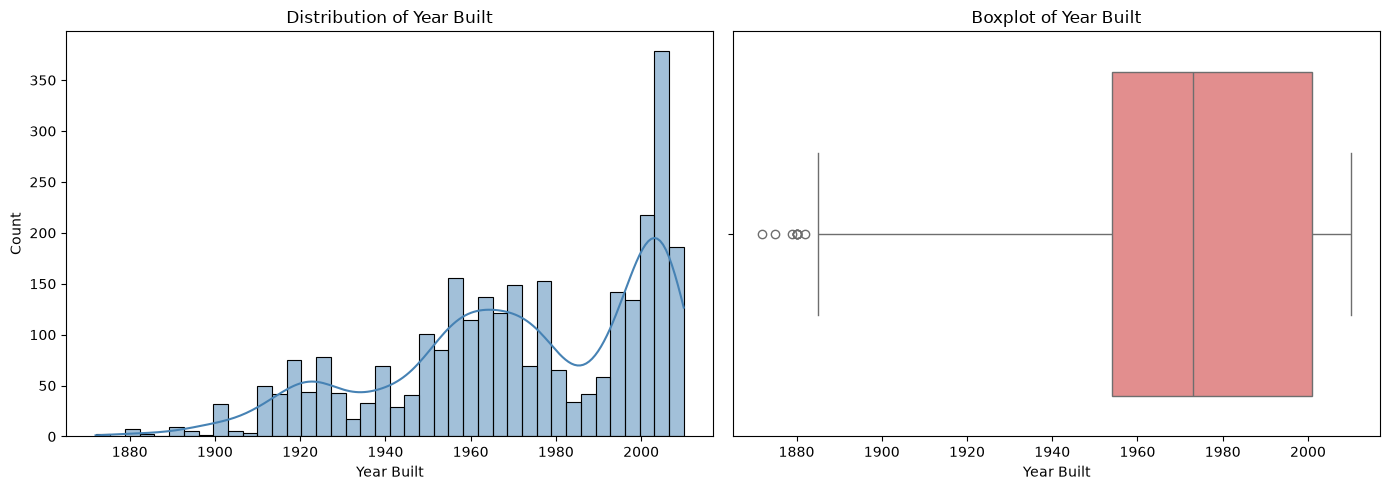

count    2930.000000
mean     1971.356314
std        30.245361
min      1872.000000
25%      1954.000000
50%      1973.000000
75%      2001.000000
max      2010.000000
Name: Year Built, dtype: float64
Skewness : -0.604
Kurtosis : -0.502


In [41]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['Year Built'], bins=40, kde=True, color='steelblue', ax=axes[0])
axes[0].set_title('Distribution of Year Built')
axes[0].set_xlabel('Year Built')
sns.boxplot(x=df['Year Built'], color='lightcoral', ax=axes[1])
axes[1].set_title('Boxplot of Year Built')
plt.tight_layout()
plt.show()
print(df['Year Built'].describe())
print(f"Skewness : {df['Year Built'].skew():.3f}")
print(f"Kurtosis : {df['Year Built'].kurtosis():.3f}")

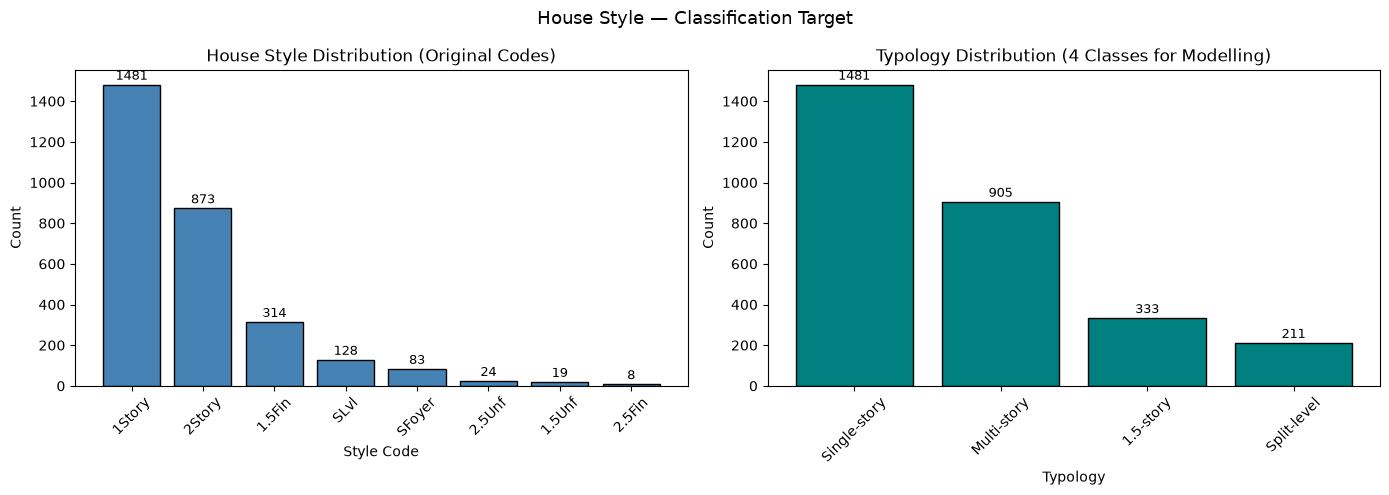

Original code counts:
House Style
1Story    1481
2Story     873
1.5Fin     314
SLvl       128
SFoyer      83
2.5Unf      24
1.5Unf      19
2.5Fin       8

Mapped to 4 typologies:
House Style
Single-story    1481
Multi-story      905
1.5-story        333
Split-level      211


In [42]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Left: original 8 style codes ---
style_counts = house_style_target.value_counts().sort_values(ascending=False)
axes[0].bar(style_counts.index, style_counts.values, color='steelblue', edgecolor='black')
axes[0].set_title('House Style Distribution (Original Codes)')
axes[0].set_xlabel('Style Code')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=45)
for bar, val in zip(axes[0].patches, style_counts.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 10,
                 str(val), ha='center', va='bottom', fontsize=9)

# --- Right: 4 typology classes after grouping ---
typology_map = {
    '1Story': 'Single-story',
    '2Story': 'Multi-story', '2.5Fin': 'Multi-story', '2.5Unf': 'Multi-story',
    '1.5Fin': '1.5-story',   '1.5Unf': '1.5-story',
    'SLvl':   'Split-level', 'SFoyer': 'Split-level',
}
typo_counts = house_style_target.map(typology_map).value_counts().sort_values(ascending=False)
axes[1].bar(typo_counts.index, typo_counts.values, color='teal', edgecolor='black')
axes[1].set_title('Typology Distribution (4 Classes for Modelling)')
axes[1].set_xlabel('Typology')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=45)
for bar, val in zip(axes[1].patches, typo_counts.values):
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 10,
                 str(val), ha='center', va='bottom', fontsize=9)

plt.suptitle('House Style — Classification Target', fontsize=13)
plt.tight_layout()
plt.show()

print('Original code counts:')
print(style_counts.to_string())
print(f'\nMapped to 4 typologies:')
print(typo_counts.to_string())

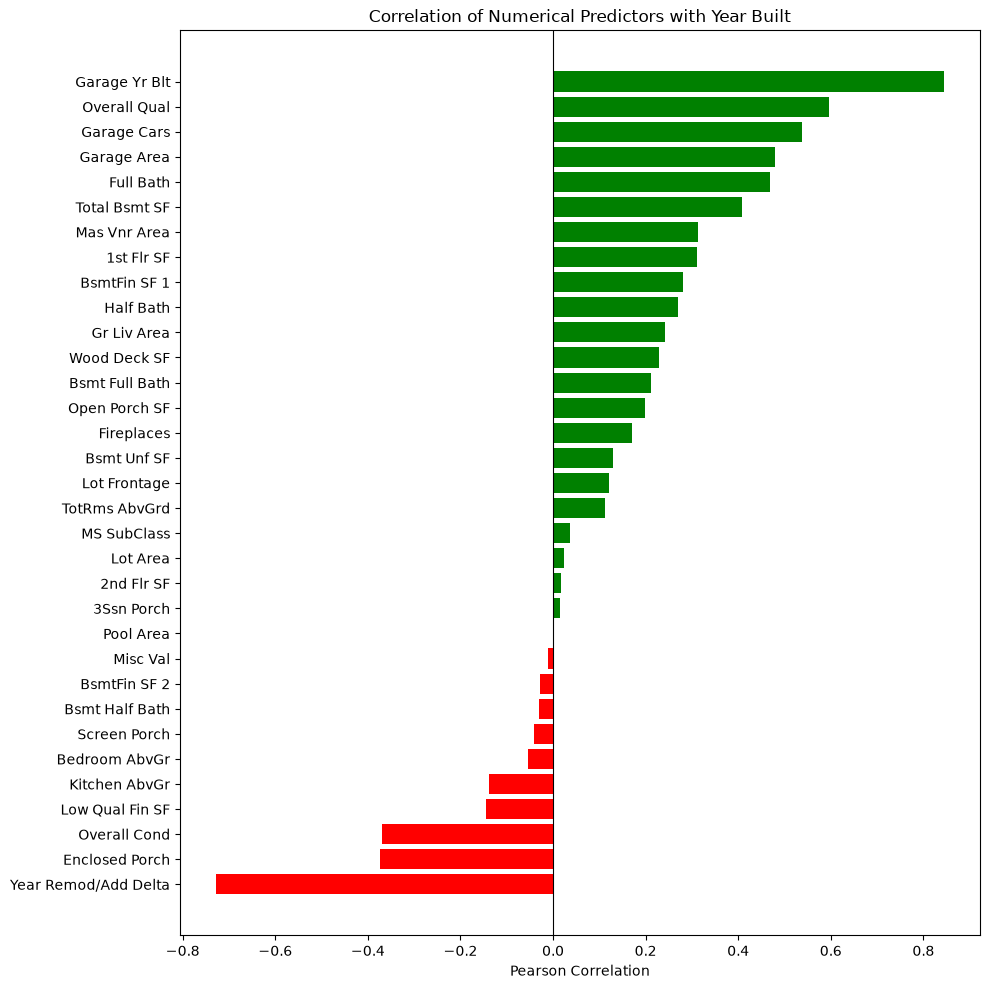

In [43]:
num_features = df.select_dtypes(include=['float64', 'int64'])
corr_with_target = (num_features.corr(numeric_only=True)['Year Built']
                    .drop('Year Built').sort_values())
colors = ['red' if x < 0 else 'green' for x in corr_with_target.values]

plt.figure(figsize=(10, 10))
plt.barh(corr_with_target.index, corr_with_target.values, color=colors)
plt.title('Correlation of Numerical Predictors with Year Built')
plt.xlabel('Pearson Correlation')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

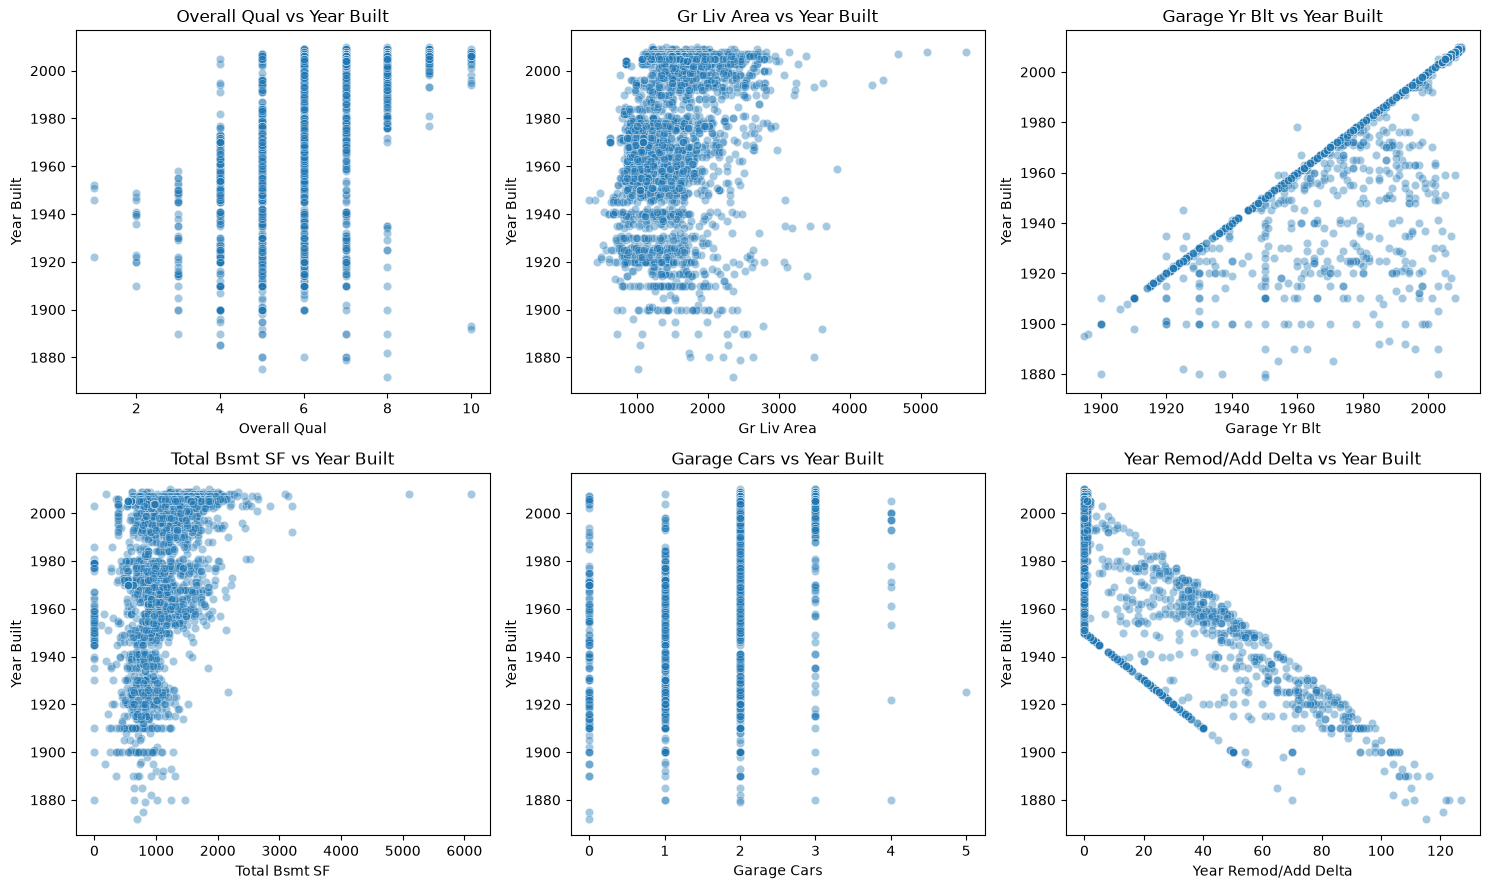

In [44]:
key_predictors = ['Overall Qual', 'Gr Liv Area', 'Garage Yr Blt',
                  'Total Bsmt SF', 'Garage Cars', 'Year Remod/Add Delta']
plt.figure(figsize=(15, 9))
for i, col in enumerate(key_predictors, 1):
    plt.subplot(2, 3, i)
    sns.scatterplot(x=df[col], y=df['Year Built'], alpha=0.4)
    plt.xlabel(col)
    plt.ylabel('Year Built')
    plt.title(f'{col} vs Year Built')
plt.tight_layout()
plt.show()

## Missing Values

Columns and rows with missing data are inspected to decide on an appropriate imputation strategy for each variable.

In [45]:
lst_null_values = df.columns[df.isnull().any()].tolist()
print('Columns with missing values:', lst_null_values)

Columns with missing values: ['Lot Frontage', 'Mas Vnr Type', 'Mas Vnr Area', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin SF 1', 'BsmtFin Type 2', 'BsmtFin SF 2', 'Bsmt Unf SF', 'Total Bsmt SF', 'Electrical', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Fireplace Qu', 'Garage Type', 'Garage Yr Blt', 'Garage Finish', 'Garage Cars', 'Garage Area', 'Garage Qual', 'Garage Cond']


In [46]:
num_clos = df.select_dtypes(include=['float64', 'int64']).columns.tolist()
num_cols_null = [col for col in lst_null_values if col in num_clos]
print('Numerical columns with NaNs:', num_cols_null)

Numerical columns with NaNs: ['Lot Frontage', 'Mas Vnr Area', 'BsmtFin SF 1', 'BsmtFin SF 2', 'Bsmt Unf SF', 'Total Bsmt SF', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Garage Yr Blt', 'Garage Cars', 'Garage Area']


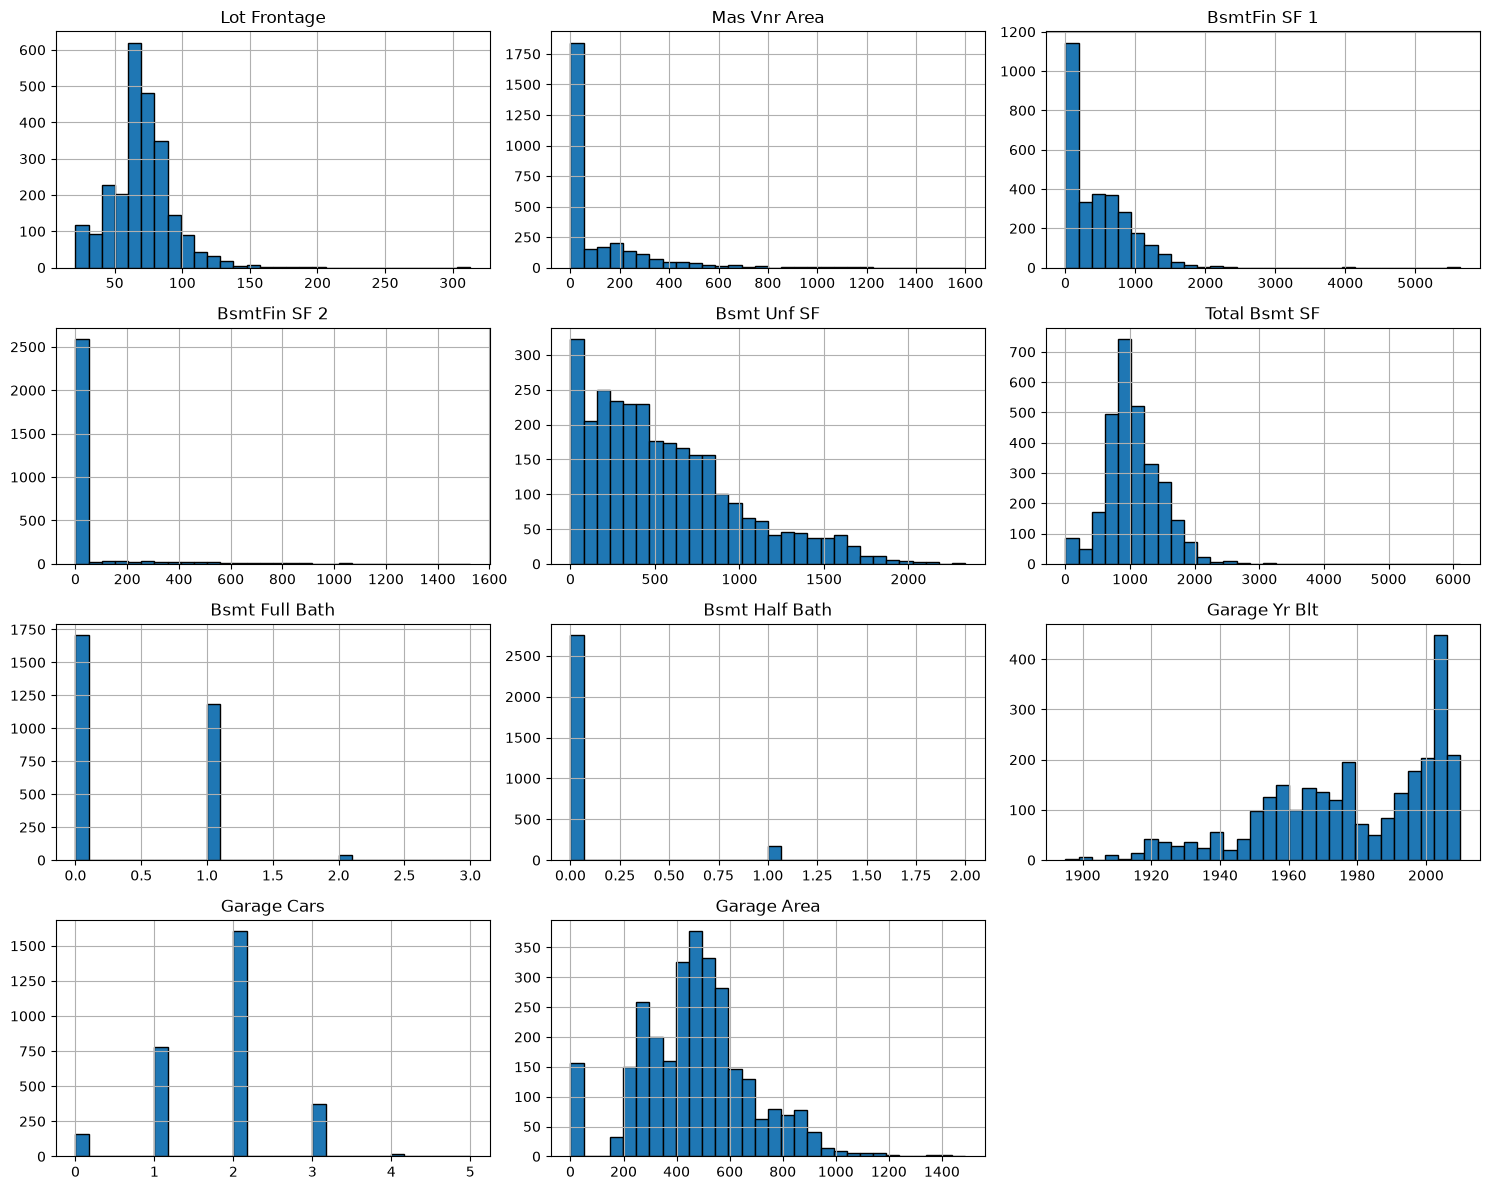

In [47]:
df[num_cols_null].hist(figsize=(15, 12), bins=30, edgecolor='black')
plt.tight_layout()
plt.show()

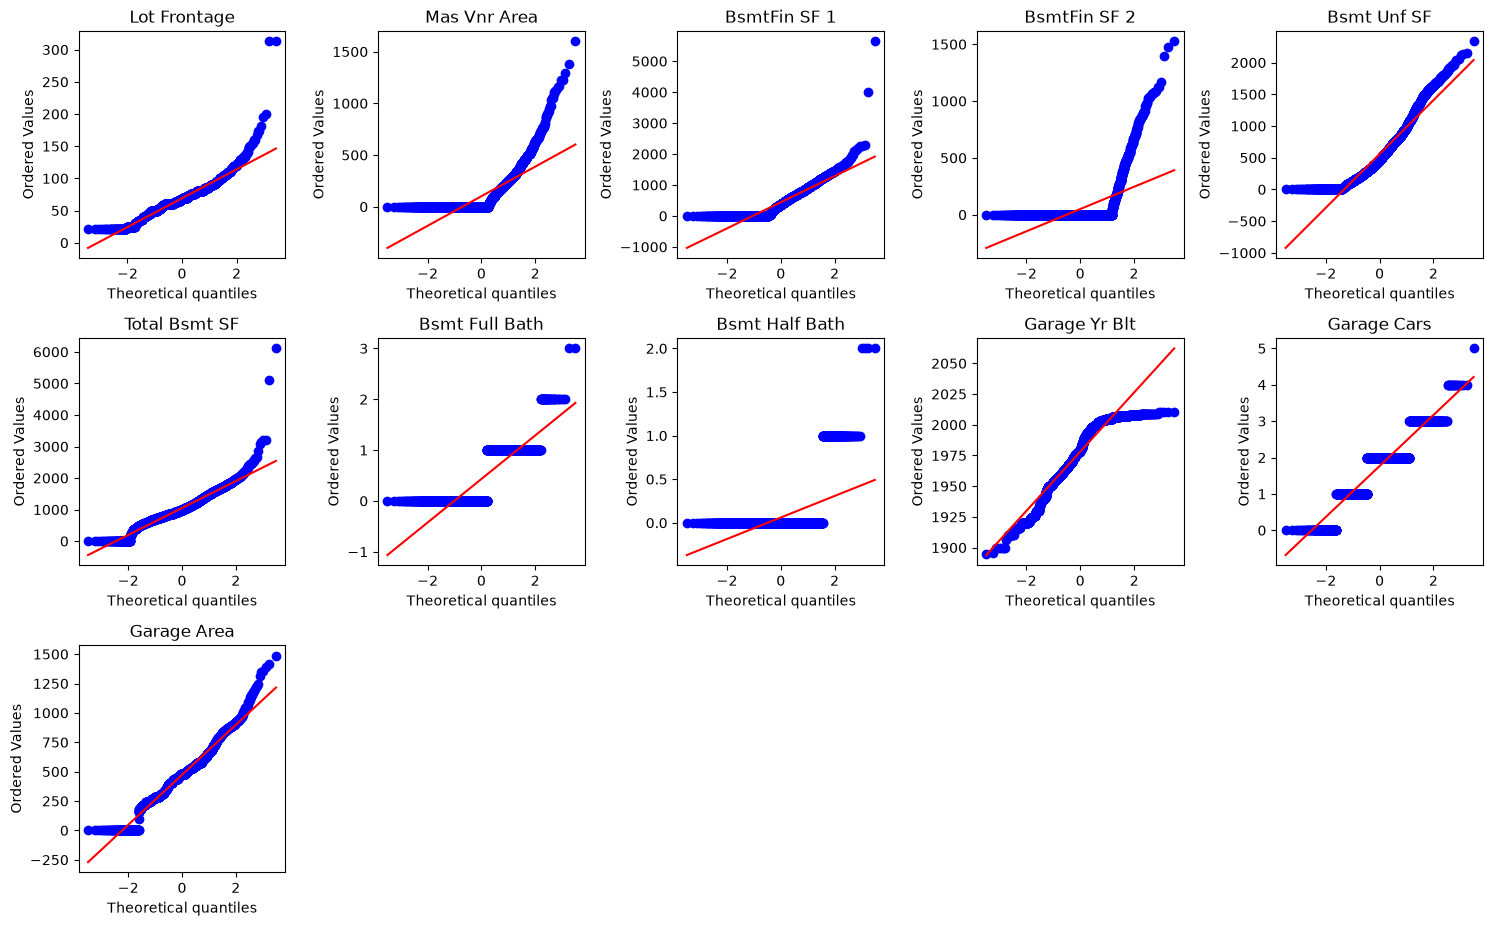

In [48]:
plt.figure(figsize=(15, 12))
for i, column in enumerate(num_cols_null, 1):
    plt.subplot(4, 5, i)
    stats.probplot(df[column].dropna(), dist='norm', plot=plt)
    plt.title(column)
plt.tight_layout()
plt.show()

In [49]:
skewness = df[num_cols_null].apply(lambda x: skew(x.dropna()))
kurt     = df[num_cols_null].apply(lambda x: kurtosis(x.dropna()))
norm_null_df = pd.DataFrame({'Skewness': skewness, 'Kurtosis': kurt})
print(norm_null_df.sort_values(by=['Skewness', 'Kurtosis']))

                Skewness   Kurtosis
Garage Yr Blt  -0.663794  -0.370656
Garage Cars    -0.219724   0.242504
Garage Area     0.241870   0.947353
Bsmt Full Bath  0.616323  -0.748761
Bsmt Unf SF     0.922580   0.406779
Total Bsmt SF   1.155612   9.117977
BsmtFin SF 1    1.415457   6.845533
Lot Frontage    1.498146  11.209384
Mas Vnr Area    2.605639   9.268606
Bsmt Half Bath  3.938776  14.894223
BsmtFin SF 2    4.137858  18.747388


In [50]:
# include both string dtype variants for compatibility across pandas versions
cat_cols = df.select_dtypes(include=['str', 'object', 'category']).columns.tolist()
cat_cols_null = [col for col in lst_null_values if col not in num_cols_null]
print('Categorical columns:', cat_cols)
print('Categorical with NaNs:', cat_cols_null)

Categorical columns: ['MS Zoning', 'Street', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1', 'Condition 2', 'Bldg Type', 'Roof Style', 'Roof Matl', 'Exterior 1st', 'Exterior 2nd', 'Mas Vnr Type', 'Exter Qual', 'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin Type 2', 'Heating', 'Heating QC', 'Central Air', 'Electrical', 'Kitchen Qual', 'Functional', 'Fireplace Qu', 'Garage Type', 'Garage Finish', 'Garage Qual', 'Garage Cond', 'Paved Drive', 'Sale Type', 'Sale Condition']
Categorical with NaNs: ['Mas Vnr Type', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin Type 2', 'Electrical', 'Fireplace Qu', 'Garage Type', 'Garage Finish', 'Garage Qual', 'Garage Cond']


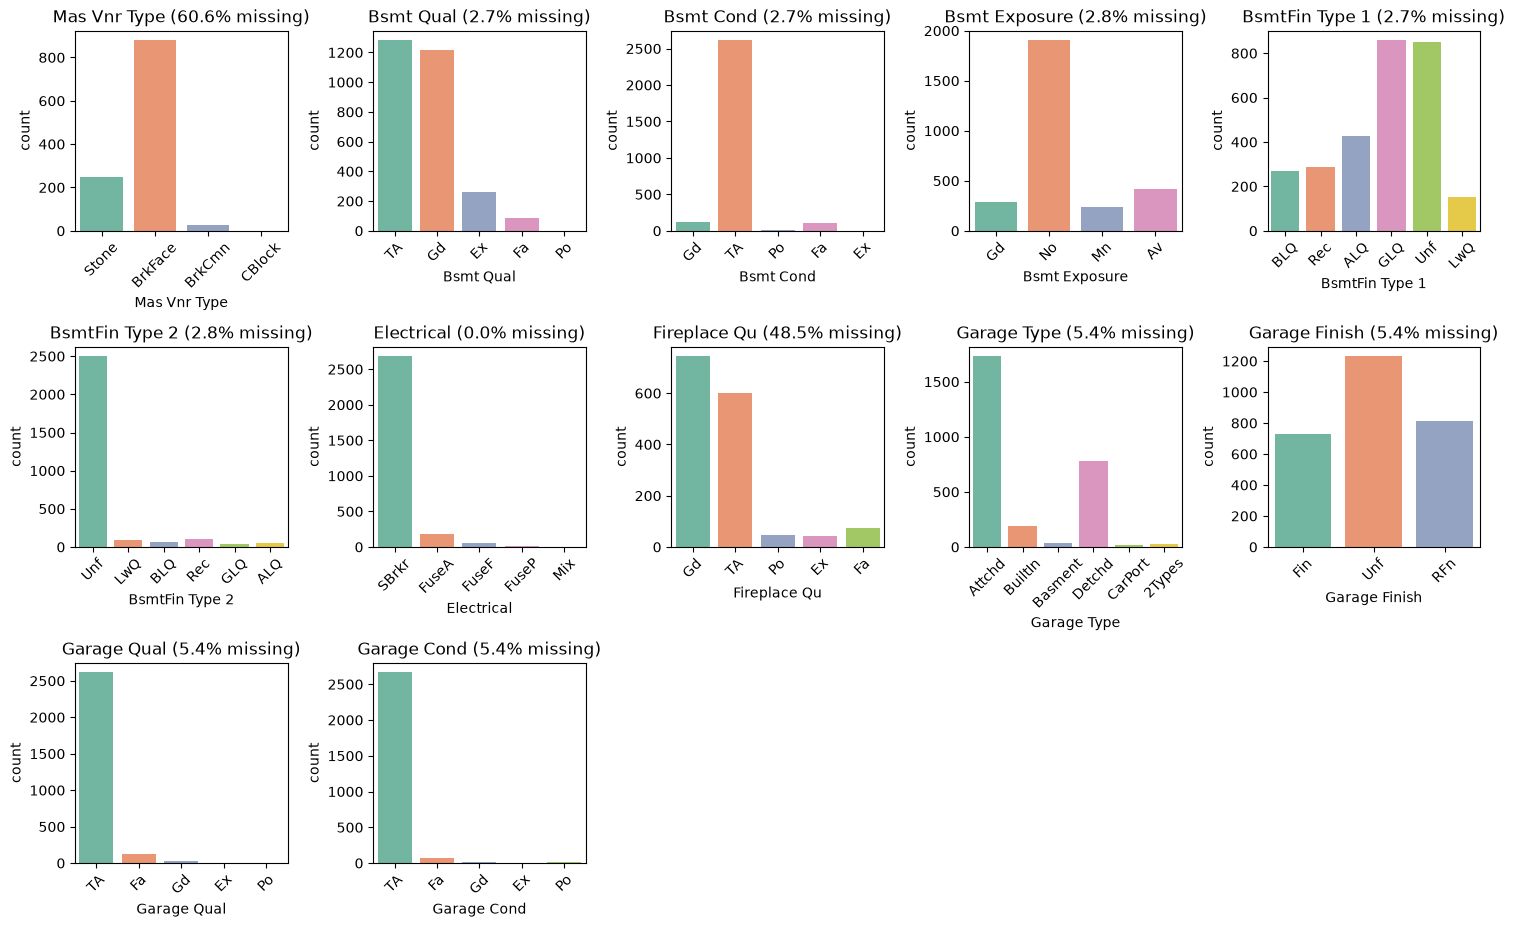

In [51]:
plt.figure(figsize=(15, 12))
for i, column in enumerate(cat_cols_null, 1):
    plt.subplot(4, 5, i)
    sns.countplot(data=df, x=column, hue=column, palette='Set2', legend=False)
    pct = df[column].isnull().mean() * 100
    plt.title(f'{column} ({pct:.1f}% missing)')
    plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Outlier Analysis

Box plots and histograms are used to identify features with extreme values. The skewness and kurtosis values below inform whether transformation or capping is needed before modelling. These statistics are computed on the full dataset for exploratory purposes only; the imputers, power transforms, and scalers used for modelling are fitted exclusively on the training fold inside the pipeline defined later in this notebook.



In [52]:
def Visualize_box_hist(df, n_rows, cols):
    fig, axes = plt.subplots(n_rows, 2, figsize=(14, 4 * n_rows))
    for i, column in enumerate(cols):
        sns.histplot(df[column], bins=30, color='skyblue', ax=axes[i, 0])
        axes[i, 0].set_title(f'Histogram of {column}')
        sns.boxplot(y=df[column], ax=axes[i, 1])
        axes[i, 1].set_title(f'Box Plot of {column}')
    plt.tight_layout()
    plt.show()

Visualize_box_hist(df, len(num_clos), num_clos)

In [53]:
skew_kurt = {}
for column in num_clos:
    col_skew = df[column].skew()
    col_kurt = df[column].kurtosis()
    skew_kurt[column] = {'Skewness': col_skew, 'Kurtosis': col_kurt}
    print(f'{column:30s}  skew={col_skew:+.3f}  kurt={col_kurt:+.3f}')

MS SubClass                     skew=+1.358  kurt=+1.387
Lot Frontage                    skew=+1.499  kurt=+11.235
Lot Area                        skew=+12.821  kurt=+265.024
Overall Qual                    skew=+0.191  kurt=+0.052
Overall Cond                    skew=+0.574  kurt=+1.491
Year Built                      skew=-0.604  kurt=-0.502
Mas Vnr Area                    skew=+2.607  kurt=+9.287
BsmtFin SF 1                    skew=+1.416  kurt=+6.859
BsmtFin SF 2                    skew=+4.140  kurt=+18.781
Bsmt Unf SF                     skew=+0.923  kurt=+0.410
Total Bsmt SF                   skew=+1.156  kurt=+9.136
1st Flr SF                      skew=+1.469  kurt=+6.969
2nd Flr SF                      skew=+0.866  kurt=-0.415
Low Qual Fin SF                 skew=+12.118  kurt=+175.607
Gr Liv Area                     skew=+1.274  kurt=+4.138
Bsmt Full Bath                  skew=+0.617  kurt=-0.748
Bsmt Half Bath                  skew=+3.941  kurt=+14.922
Full Bath             

In [54]:
zero_skew_kurt = [k for k, v in skew_kurt.items()
                   if v['Skewness'] == 0 and v['Kurtosis'] == 0]
variance = df[zero_skew_kurt].var()
print('Zero-variance columns (if any):')
print(variance)

Zero-variance columns (if any):
Series([], dtype: float64)


In [55]:
# update column list
num_clos = df.select_dtypes(include=['float64', 'int64']).columns.tolist()

In [56]:
# check for negative values before applying Yeo-Johnson
neg_cols = [col for col in num_clos if (df[col] < 0).any()]
print('Columns with negative values:', neg_cols if neg_cols else 'none')

Columns with negative values: none


In [57]:
# skewness and kurtosis values used to assign features to standardisation or normalisation
skew_kurt = {}
for column in num_clos:
    col_skew = df[column].skew()
    col_kurt = df[column].kurtosis()
    skew_kurt[column] = {'Skewness': col_skew, 'Kurtosis': col_kurt}
    print(f'{column:30s}  skew={col_skew:+.3f}  kurt={col_kurt:+.3f}')

MS SubClass                     skew=+1.358  kurt=+1.387
Lot Frontage                    skew=+1.499  kurt=+11.235
Lot Area                        skew=+12.821  kurt=+265.024
Overall Qual                    skew=+0.191  kurt=+0.052
Overall Cond                    skew=+0.574  kurt=+1.491
Year Built                      skew=-0.604  kurt=-0.502
Mas Vnr Area                    skew=+2.607  kurt=+9.287
BsmtFin SF 1                    skew=+1.416  kurt=+6.859
BsmtFin SF 2                    skew=+4.140  kurt=+18.781
Bsmt Unf SF                     skew=+0.923  kurt=+0.410
Total Bsmt SF                   skew=+1.156  kurt=+9.136
1st Flr SF                      skew=+1.469  kurt=+6.969
2nd Flr SF                      skew=+0.866  kurt=-0.415
Low Qual Fin SF                 skew=+12.118  kurt=+175.607
Gr Liv Area                     skew=+1.274  kurt=+4.138
Bsmt Full Bath                  skew=+0.617  kurt=-0.748
Bsmt Half Bath                  skew=+3.941  kurt=+14.922
Full Bath             

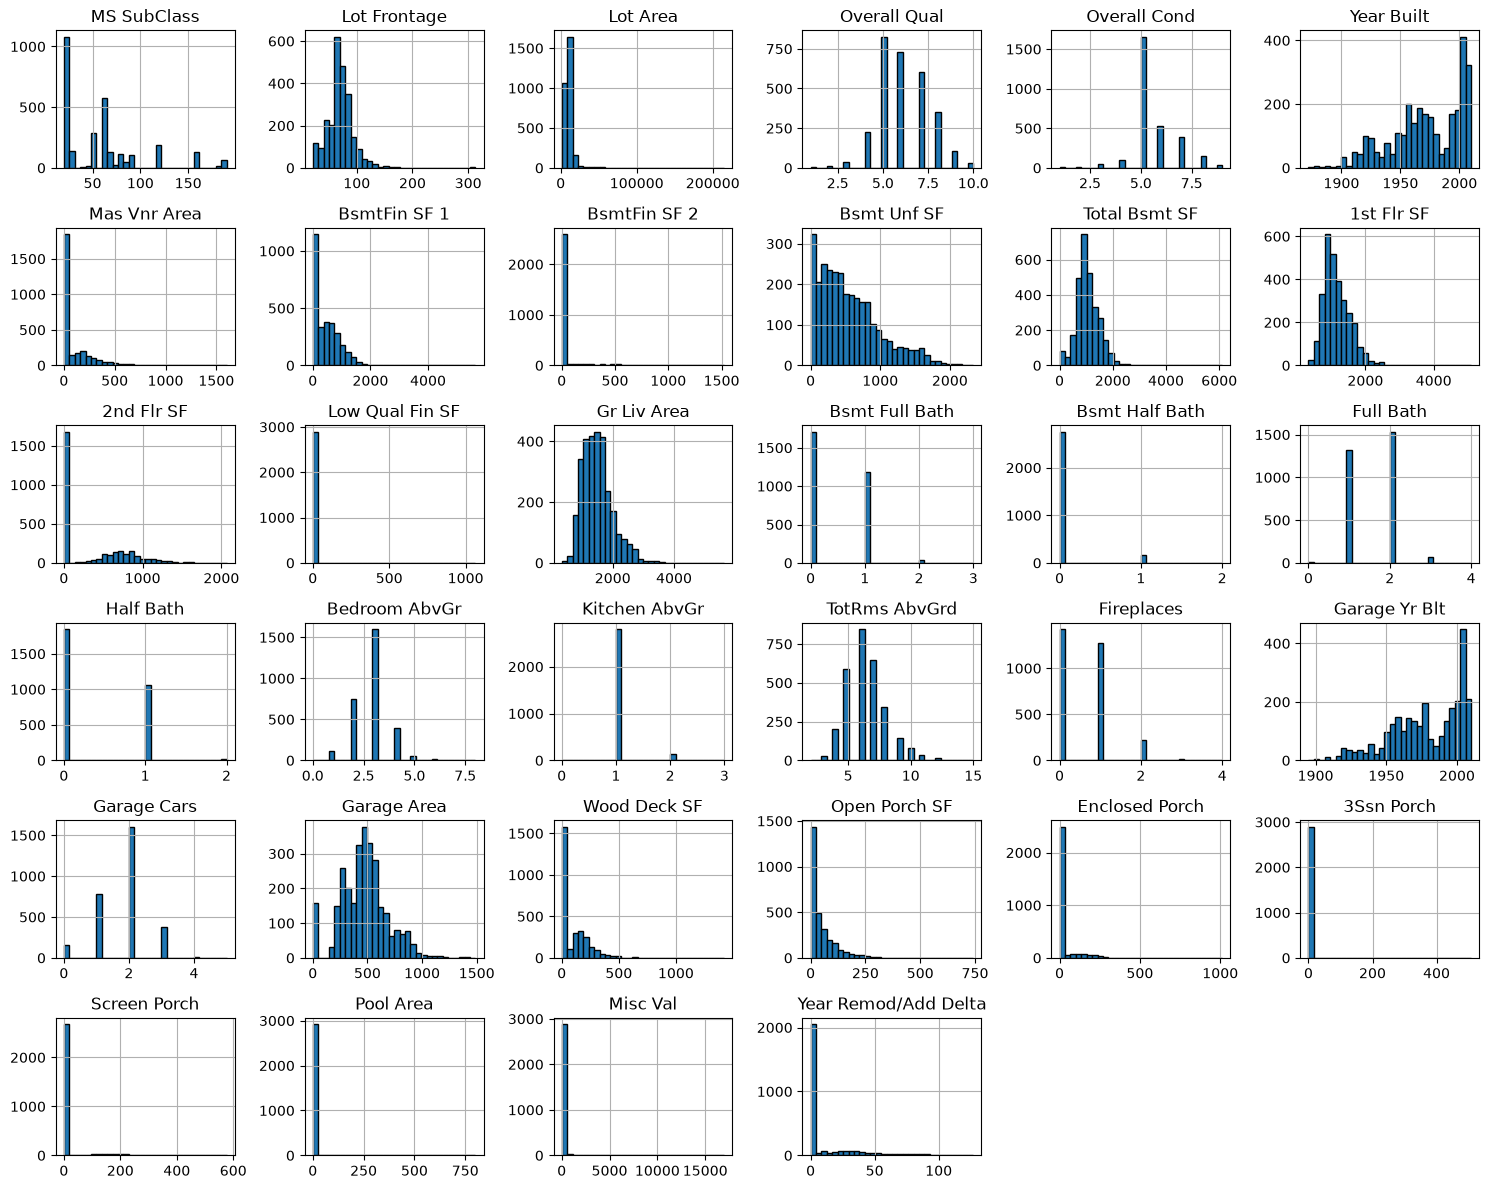

In [58]:
df_plot = df[num_clos].replace([np.inf, -np.inf], np.nan)
df_plot.hist(figsize=(15, 12), bins=30, edgecolor='black')
plt.tight_layout()
plt.show()

## Scaling and Encoding

Based on the skewness and kurtosis checks above, numerical features are divided into two groups. Those with approximately symmetric distributions are standardised using a Yeo-Johnson transform followed by a standard scaler; features with higher skew are normalised using the same power transform followed by min-max scaling.

Nine numeric columns are not assigned to either group and are excluded from the regression feature matrix: `BsmtFin SF 2`, `Low Qual Fin SF`, `Bsmt Half Bath`, `Kitchen AbvGr`, `Enclosed Porch`, `3Ssn Porch`, `Screen Porch`, `Pool Area`, and `Misc Val`. Each has a skewness above 3.9 and is dominated by a single value (typically zero) for the large majority of observations, so assigning them to either scaling group would provide negligible additional information while destabilising the Yeo-Johnson fit. These columns are retained in the classification feature set below, where they are imputed and standardised without this restriction.

For categorical variables, ordinal encoding is applied to features with a natural ordering (quality and condition ratings), one-hot encoding to low-cardinality nominal features, and binary encoding to high-cardinality features to avoid excessive dimensionality.

In [59]:
standardization = [
    'Lot Frontage', 'Lot Area', 'Overall Qual', 'Total Bsmt SF', '1st Flr SF',
    'Gr Liv Area', 'Full Bath', 'Year Remod/Add Delta', 'BsmtFin SF 1',
    'Bsmt Unf SF', 'Garage Yr Blt', 'Garage Cars', 'TotRms AbvGrd',
    'Garage Area', 'Overall Cond', 'Bedroom AbvGr',
]
normalization = [
    'MS SubClass', 'Mas Vnr Area', 'Half Bath', '2nd Flr SF',
    'Wood Deck SF', 'Open Porch SF', 'Bsmt Full Bath', 'Fireplaces',
]
print(f'Standardize : {len(standardization)} features')
print(f'Normalize   : {len(normalization)} features')

Standardize : 16 features
Normalize   : 8 features


In [60]:
ordinal_cat = [
    'Lot Shape', 'Land Slope', 'Exter Qual', 'Exter Cond', 'Bsmt Qual',
    'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin Type 2',
    'Heating QC', 'Kitchen Qual', 'Fireplace Qu', 'Garage Qual', 'Garage Cond',
    'Garage Finish', 'Functional', 'Paved Drive', 'Street', 'Central Air',
    'Electrical', 'Utilities',
]
categories = [
    ['Reg', 'IR1', 'IR2', 'IR3'],
    ['Gtl', 'Mod', 'Sev'],
    ['Ex', 'Gd', 'TA', 'Fa'],
    ['Ex', 'Gd', 'TA', 'Fa', 'Po'],
    ['Ex', 'Gd', 'TA', 'Fa', 'Po', 'Unknown'],
    ['Ex', 'Gd', 'TA', 'Fa', 'Po'],
    ['Gd', 'Av', 'Mn', 'No'],
    ['GLQ', 'ALQ', 'BLQ', 'Rec', 'LwQ', 'Unf', 'Unknown'],
    ['GLQ', 'ALQ', 'BLQ', 'Rec', 'LwQ', 'Unf'],
    ['Ex', 'Gd', 'TA', 'Fa', 'Po'],
    ['Ex', 'Gd', 'TA', 'Fa', 'Po'],
    ['Ex', 'Gd', 'TA', 'Fa', 'Po', 'Unknown'],
    ['Ex', 'Gd', 'TA', 'Fa', 'Po'],
    ['Ex', 'Gd', 'TA', 'Fa', 'Po'],
    ['Fin', 'RFn', 'Unf', 'Unknown'],
    ['Typ', 'Min1', 'Min2', 'Mod', 'Maj1', 'Maj2', 'Sev', 'Sal'],
    ['Y', 'P', 'N'],
    ['Pave', 'Grvl'],
    ['Y', 'N'],
    ['SBrkr', 'FuseA', 'FuseF', 'FuseP', 'Mix'],
    ['AllPub', 'NoSewr', 'NoSeWa'],
]

In [61]:
def check_category_type(df, threshold=10):
    # Classifies each categorical column as ordinal (pre-defined order, see
    # `ordinal_cat` above), high-cardinality (more than `threshold` unique
    # values - encoded later via BinaryEncoder to limit dimensionality), or
    # nominal (remaining low-cardinality, unordered categories).
    variable_info = {}
    nominal_cat   = []
    hc_cat        = []
    for col in cat_cols:
        n_unique = df[col].nunique()
        is_ord   = col in ordinal_cat
        if n_unique > threshold:
            enc = 'High cardinality'
            hc_cat.append(col)
        elif is_ord:
            enc = 'Ordinal'
        else:
            enc = 'Nominal'
            nominal_cat.append(col)
        variable_info[col] = {'Unique Categories': n_unique, 'Category Type': enc}
    return pd.DataFrame(variable_info).T, nominal_cat, hc_cat

In [62]:
variable_analysis, nominal_cat, hc_cat = check_category_type(df)
print(variable_analysis)
print(f'\nNominal         : {nominal_cat}')
print(f'High-cardinality: {hc_cat}')

               Unique Categories     Category Type
MS Zoning                      7           Nominal
Street                         2           Ordinal
Lot Shape                      4           Ordinal
Land Contour                   4           Nominal
Utilities                      3           Ordinal
Lot Config                     5           Nominal
Land Slope                     3           Ordinal
Neighborhood                  28  High cardinality
Condition 1                    9           Nominal
Condition 2                    8           Nominal
Bldg Type                      5           Nominal
Roof Style                     6           Nominal
Roof Matl                      8           Nominal
Exterior 1st                  16  High cardinality
Exterior 2nd                  17  High cardinality
Mas Vnr Type                   4           Nominal
Exter Qual                     4           Ordinal
Exter Cond                     5           Ordinal
Foundation                     

## Preprocessing Pipeline

The five transformation groups are assembled into a single `ColumnTransformer`. Wrapping all steps inside this pipeline means that imputers, scalers and encoders are fitted only on the training data, so no information from the test set influences the learned parameters.

In [63]:
# Median imputation is robust to the outliers already observed in this group;
# Yeo-Johnson (which, unlike Box-Cox, accepts zero/negative inputs) reduces
# residual skew before standardising to zero mean / unit variance.
numeric_std = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='median')),
    ('power',  PowerTransformer(method='yeo-johnson', standardize=True)),
])
# Same de-skewing step, but scaled to [0, 1] instead of standardised - used
# for the more heavily skewed feature group identified in the EDA above.
numeric_norm = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='median')),
    ('power',  PowerTransformer(method='yeo-johnson', standardize=False)),
    ('scale',  MinMaxScaler()),
])
# handle_unknown='use_encoded_value' prevents a failure if a category absent
# from the training fold appears in a validation or test fold.
ordinal_pipe = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('encode', OrdinalEncoder(categories=categories,
                              handle_unknown='use_encoded_value',
                              unknown_value=-1)),
])
nominal_pipe = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])
# BinaryEncoder keeps the output dimensionality low for high-cardinality
# columns (e.g. Neighborhood, 28 categories) relative to one-hot encoding.
highcard_pipe = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('encode', BinaryEncoder()),
])

# remainder='drop': any column not assigned to one of the five groups above
# (the nine sparse numeric columns noted in the previous section) is excluded
# from the regression feature matrix.
preprocessor = ColumnTransformer(
    transformers=[
        ('std',     numeric_std,   standardization),
        ('norm',    numeric_norm,  normalization),
        ('ordinal', ordinal_pipe,  ordinal_cat),
        ('onehot',  nominal_pipe,  nominal_cat),
        ('binary',  highcard_pipe, hc_cat),
    ],
    remainder='drop',
)
print('Preprocessor built.')

Preprocessor built.


## Train/Test Split

The original CSV is re-read and only minimal, deterministic operations are applied at this stage — removing sparse columns, dropping rows with missing target values, and computing the engineered feature (including the two data quality corrections applied during EDA above). Scaling and imputation are handled by the pipeline during training.

In [64]:
df_model = pd.read_csv('AmesHousing.csv')
_missing = df_model.isnull().mean()
df_model.drop(columns=_missing[_missing > 0.70].index, inplace=True)
df_model.dropna(subset=['Year Built', 'House Style'], inplace=True)

# Same two data quality corrections applied during EDA (see Feature Engineering above).
df_model.loc[df_model['Garage Yr Blt'] > df_model['Year Built'].max(), 'Garage Yr Blt'] = np.nan
df_model['Year Remod/Add Delta'] = (df_model['Year Remod/Add'] - df_model['Year Built']).clip(lower=0)

house_style_target = df_model['House Style'].copy()
df_model.drop(columns=['Order', 'PID', 'SalePrice', 'House Style',
                       'Year Remod/Add', 'Yr Sold', 'Mo Sold'], inplace=True)

y = df_model['Year Built']
X = df_model.drop(columns='Year Built')

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f'Feature matrix : {X.shape}')
print(f'Train {X_train.shape}  |  Test {X_test.shape}')

Feature matrix : (2930, 71)
Train (2344, 71)  |  Test (586, 71)


## Classification Feature Set

For the typology task, a separate feature set is constructed from spatial and structural measurements only. Features that carry information about when a house was built or modified (`Year Built`, `Garage Yr Blt`, `Year Remod/Add Delta`) are excluded, as is `MS SubClass`, whose codes directly encode storey configuration and would therefore constitute leakage.

In [65]:
X_reg = X
y_reg = y
preprocessor_reg = preprocessor

y_clf = house_style_target.copy()
typology_map = {
    '1Story': 'Single-story',
    '2Story': 'Multi-story', '2.5Fin': 'Multi-story', '2.5Unf': 'Multi-story',
    '1.5Fin': '1.5-story',   '1.5Unf': '1.5-story',
    'SLvl':   'Split-level', 'SFoyer': 'Split-level',
}
y_clf = y_clf.map(typology_map).fillna(y_clf)

clf_blocklist = {'Year Built', 'Garage Yr Blt', 'Year Remod/Add Delta', 'MS SubClass'}
clf_features  = [c for c in X.select_dtypes(include=['number']).columns
                 if c not in clf_blocklist]
X_clf = X[clf_features]

preprocessor_clf = ColumnTransformer(
    transformers=[('geom', Pipeline(steps=[
        ('impute', SimpleImputer(strategy='median')),
        ('scale',  StandardScaler()),
    ]), clf_features)],
    remainder='drop',
)

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42)

X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf)

print('Class distribution:')
print(y_clf.value_counts())
print(f'\nRegression     : train {X_train_reg.shape}  test {X_test_reg.shape}')
print(f'Classification : train {X_train_clf.shape}  test {X_test_clf.shape}')
print(f'Geometry features ({len(clf_features)}): {clf_features}')

Class distribution:
House Style
Single-story    1481
Multi-story      905
1.5-story        333
Split-level      211
Name: count, dtype: int64

Regression     : train (2344, 71)  test (586, 71)
Classification : train (2344, 30)  test (586, 30)
Geometry features (30): ['Lot Frontage', 'Lot Area', 'Overall Qual', 'Overall Cond', 'Mas Vnr Area', 'BsmtFin SF 1', 'BsmtFin SF 2', 'Bsmt Unf SF', 'Total Bsmt SF', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF', 'Gr Liv Area', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath', 'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'TotRms AbvGrd', 'Fireplaces', 'Garage Cars', 'Garage Area', 'Wood Deck SF', 'Open Porch SF', 'Enclosed Porch', '3Ssn Porch', 'Screen Porch', 'Pool Area', 'Misc Val']


## Saving the Outputs

The train/test splits and preprocessor objects are written to `preprocessed_data.pkl` so the modelling notebooks can load a consistent dataset without re-running this notebook.

In [66]:
artifacts = {
    # Shared raw matrix
    'X': X, 'y': y,
    # Regression
    'X_reg': X_reg, 'y_reg': y_reg,
    'X_train': X_train, 'X_test': X_test,
    'y_train': y_train, 'y_test': y_test,
    'X_train_reg': X_train_reg, 'X_test_reg': X_test_reg,
    'y_train_reg': y_train_reg, 'y_test_reg': y_test_reg,
    'preprocessor': preprocessor,
    'preprocessor_reg': preprocessor_reg,
    # Classification
    'X_clf': X_clf, 'y_clf': y_clf,
    'X_train_clf': X_train_clf, 'X_test_clf': X_test_clf,
    'y_train_clf': y_train_clf, 'y_test_clf': y_test_clf,
    'preprocessor_clf': preprocessor_clf,
    'clf_features': clf_features,
}
with open('preprocessed_data.pkl', 'wb') as f:
    pickle.dump(artifacts, f)
print('Saved: preprocessed_data.pkl')
print('Keys:', list(artifacts.keys()))

Saved: preprocessed_data.pkl
Keys: ['X', 'y', 'X_reg', 'y_reg', 'X_train', 'X_test', 'y_train', 'y_test', 'X_train_reg', 'X_test_reg', 'y_train_reg', 'y_test_reg', 'preprocessor', 'preprocessor_reg', 'X_clf', 'y_clf', 'X_train_clf', 'X_test_clf', 'y_train_clf', 'y_test_clf', 'preprocessor_clf', 'clf_features']
